In [1]:
import shutil
import tensorflow as tf

base = r"C:\Users\goushik lap\Downloads\Facemask-20261016T093849Z-1-001\Facemask"
src = base + r"\mask_detector.model"
dst = base + r"\mask_detector.h5"

shutil.copy(src, dst)

maskNet = tf.keras.models.load_model(dst, compile=False)
print("Mask detector loaded successfully!")

Mask detector loaded successfully!


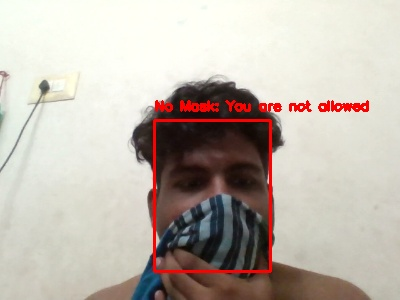

In [ ]:
# Import libraries
from pathlib import Path
import cv2
import numpy as np
import time
import tensorflow as tf
from IPython.display import display, Image, clear_output
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Set project paths
PROJECT_DIR = Path(r"C:\Users\goushik lap\Downloads\Facemask-20261016T093849Z-1-001\Facemask")
FACE_DIR = PROJECT_DIR / "face_detector"
PROTOTXT = FACE_DIR / "deploy.prototxt"
WEIGHTS = FACE_DIR / "res10_300x300_ssd_iter_140000.caffemodel"
MASK_MODEL = PROJECT_DIR / "mask_detector.h5"

# Check required files
for path in [PROTOTXT, WEIGHTS, MASK_MODEL]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

# Load the face detection model
print("Loading face detector...")
faceNet = cv2.dnn.readNetFromCaffe(str(PROTOTXT), str(WEIGHTS))

# Load the trained mask classification model
print("Loading mask detection model...")
maskNet = tf.keras.models.load_model(str(MASK_MODEL), compile=False)
print("Models loaded successfully!")


def detect_and_predict_mask(frame, faceNet, maskNet, threshold=0.5):
    h, w = frame.shape[:2]

    # Prepare image for face detection
    blob = cv2.dnn.blobFromImage(frame, 1.0, (300, 300), (104.0, 177.0, 123.0))
    faceNet.setInput(blob)
    detections = faceNet.forward()

    faces = []
    locations = []

    # Extract detected face regions
    for i in range(detections.shape[2]):
        confidence = float(detections[0, 0, i, 2])
        if confidence < threshold:
            continue

        box = detections[0, 0, i, 3:7] * np.array([w, h, w, h])
        startX, startY, endX, endY = box.astype(int)
        startX = max(0, startX)
        startY = max(0, startY)
        endX = min(w, endX)
        endY = min(h, endY)

        if endX <= startX or endY <= startY:
            continue

        # Prepare face image for MobileNetV2
        face = frame[startY:endY, startX:endX]
        face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
        face = cv2.resize(face, (224, 224))
        face = preprocess_input(face.astype("float32"))

        faces.append(face)
        locations.append((startX, startY, endX, endY))

    # Predict mask status
    if faces:
        batch = np.asarray(faces, dtype="float32")
        predictions = np.asarray(maskNet.predict(batch, verbose=0))
    else:
        predictions = np.empty((0, 2))

    return locations, predictions


# Start webcam (CAP_DSHOW is more reliable on Windows)
camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)
if not camera.isOpened():
    camera.release()
    raise RuntimeError("Webcam unavailable. Check permissions or try camera index 1.")

print("Webcam started. Interrupt the kernel (stop button) to quit.")

try:
    while True:
        # Read webcam frame
        success, frame = camera.read()
        if not success:
            print("Unable to read webcam frame.")
            break

        # Resize frame
        new_width = 400
        new_height = int(frame.shape[0] * new_width / frame.shape[1])
        frame = cv2.resize(frame, (new_width, new_height))

        # Detect faces and predict mask status
        locations, predictions = detect_and_predict_mask(frame, faceNet, maskNet)

        # Draw bounding boxes and labels
        for (box, pred) in zip(locations, predictions):
            startX, startY, endX, endY = box
            mask_score, without_mask_score = pred[:2]

            if mask_score > without_mask_score:
                label = "Mask: You are allowed"
                color = (0, 255, 0)
            else:
                label = "No Mask: You are not allowed"
                color = (0, 0, 255)

            cv2.rectangle(frame, (startX, startY), (endX, endY), color, 2)
            cv2.putText(frame, label, (startX, max(20, startY - 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 2)

        # Display frame inside Jupyter Notebook
        encoded_ok, encoded_frame = cv2.imencode(".jpg", frame)
        if encoded_ok:
            clear_output(wait=True)
            display(Image(data=encoded_frame.tobytes()))
            time.sleep(0.03)
            

except KeyboardInterrupt:
    print("Webcam stopped.")
finally:
    camera.release()
    print("Webcam resources released.")

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


   ---------------------------------------- 0.0/41.2 MB ? eta -:--:--
   - -------------------------------------- 1.3/41.2 MB 9.4 MB/s eta 0:00:05
   --- ------------------------------------ 3.4/41.2 MB 9.9 MB/s eta 0:00:04
   ----- ---------------------------------- 5.8/41.2 MB 10.6 MB/s eta 0:00:04
   ------- -------------------------------- 8.1/41.2 MB 10.9 MB/s eta 0:00:04
   ---------- ----------------------------- 10.7/41.2 MB 11.1 MB/s eta 0:00:03
   ------------ --------------------------- 13.1/41.2 MB 11.2 MB/s eta 0:00:03
   --------------- ------------------------ 15.5/41.2 MB 11.3 MB/s eta 0:00:03
   ----------------- ---------------------- 17.8/41.2 MB 11.3 MB/s eta 0:00:03
   ------------------- -------------------- 19.9/41.2 MB 11.3 MB/s eta 0:00:02
   --------------------- ------------------ 22.5/41.2 MB 11.4 MB/s eta 0:00:02
   ------------------------ --------------- 24.9/41.2 MB 11.4 MB/s eta 0:00:02
   -------------------------- ------------- 27.3/41.2 MB 11.4 MB/s 